# Assignment 4: Translation quality gaps by resource level and direction

**Fariza Ismagambetova, Aizada Sembayeva, Zhanibek Yskak** (Group SE-2418)

**Research question.** How does the translation-quality gap between low- and high-resource languages differ between translation *into* English and translation *from* English?

This notebook shows the saved results of `scripts/analyze.py` (main analysis) and `scripts/summarize_errors.py` (error analysis). It only reads files from `results/` and `figures/`; to recompute everything, run the scripts as described in the README.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

root = Path.cwd() if (Path.cwd() / "results").is_dir() else Path.cwd().parent
results = root / "results"
pd.set_option("display.float_format", "{:.5g}".format)

## 1. Data

Published chrF++ scores of three NLLB-200 models on FLORES-200 devtest (1,012 sentences per direction): 201 language-script units × 2 directions × 3 models = **1,206 scores**. Script variants of the same language are averaged, giving **195 languages: 52 high-resource** (≥ 1,000,000 training examples) and **143 low-resource**.

In [2]:
languages = pd.read_csv(results / "per_language_scores.csv")
moe = languages[languages["model"] == "moe_54b"]
print("Scores per model:", len(pd.read_csv(results / "per_script_scores.csv")) // 3)
print("Languages per group:", moe.drop_duplicates("language")["resource_group"].value_counts().to_dict())
display(moe[moe["language"] == "ace"][["language", "direction", "score", "script_ids", "raw_csv_rows"]].round(2))

Scores per model: 402
Languages per group: {'low': 143, 'high': 52}


,language,direction,score,script_ids,raw_csv_rows
780,ace,from_english,27.25,ace_Arab;ace_Latn,9449;9450
781,ace,into_english,43.9,ace_Arab;ace_Latn,48;249


## 2. Main results

* `Gap = mean(High) − mean(Low)` in each direction
* `DeltaGap = Gap_from_English − Gap_into_English` (positive = larger gap from English)

95% confidence intervals: 20,000 stratified bootstrap samples of languages. p-values: 100,000 label permutations, Holm correction across the 3 models. Seed 20261108.

In [3]:
main = pd.read_csv(results / "main_summary.csv")
table2 = main[["label", "high_into", "low_into", "gap_into", "high_from", "low_from", "gap_from"]]
display(table2.round(2))  # Table 2 in the report

,label,high_into,low_into,gap_into,high_from,low_from,gap_from
0,NLLB-200 Distilled 600M,59.84,50.17,9.67,51.58,39.12,12.47
1,NLLB-200 Dense 3.3B,63.14,53.61,9.53,54.91,41.68,13.23
2,NLLB-200 MoE 54.5B,63.63,54.85,8.79,55.56,42.49,13.07


In [4]:
table3 = main[["label", "delta_gap", "delta_gap_ci_lower", "delta_gap_ci_upper", "p_unadjusted", "p_holm"]]
display(table3.round({"delta_gap": 2, "delta_gap_ci_lower": 2, "delta_gap_ci_upper": 2,
                      "p_unadjusted": 5, "p_holm": 5}))  # Table 3 in the report

,label,delta_gap,delta_gap_ci_lower,delta_gap_ci_upper,p_unadjusted,p_holm
0,NLLB-200 Distilled 600M,2.8,0.75,4.68,0.00714,0.00714
1,NLLB-200 Dense 3.3B,3.7,1.55,5.68,0.00077,0.00154
2,NLLB-200 MoE 54.5B,4.28,2.14,6.23,0.00016,0.00048


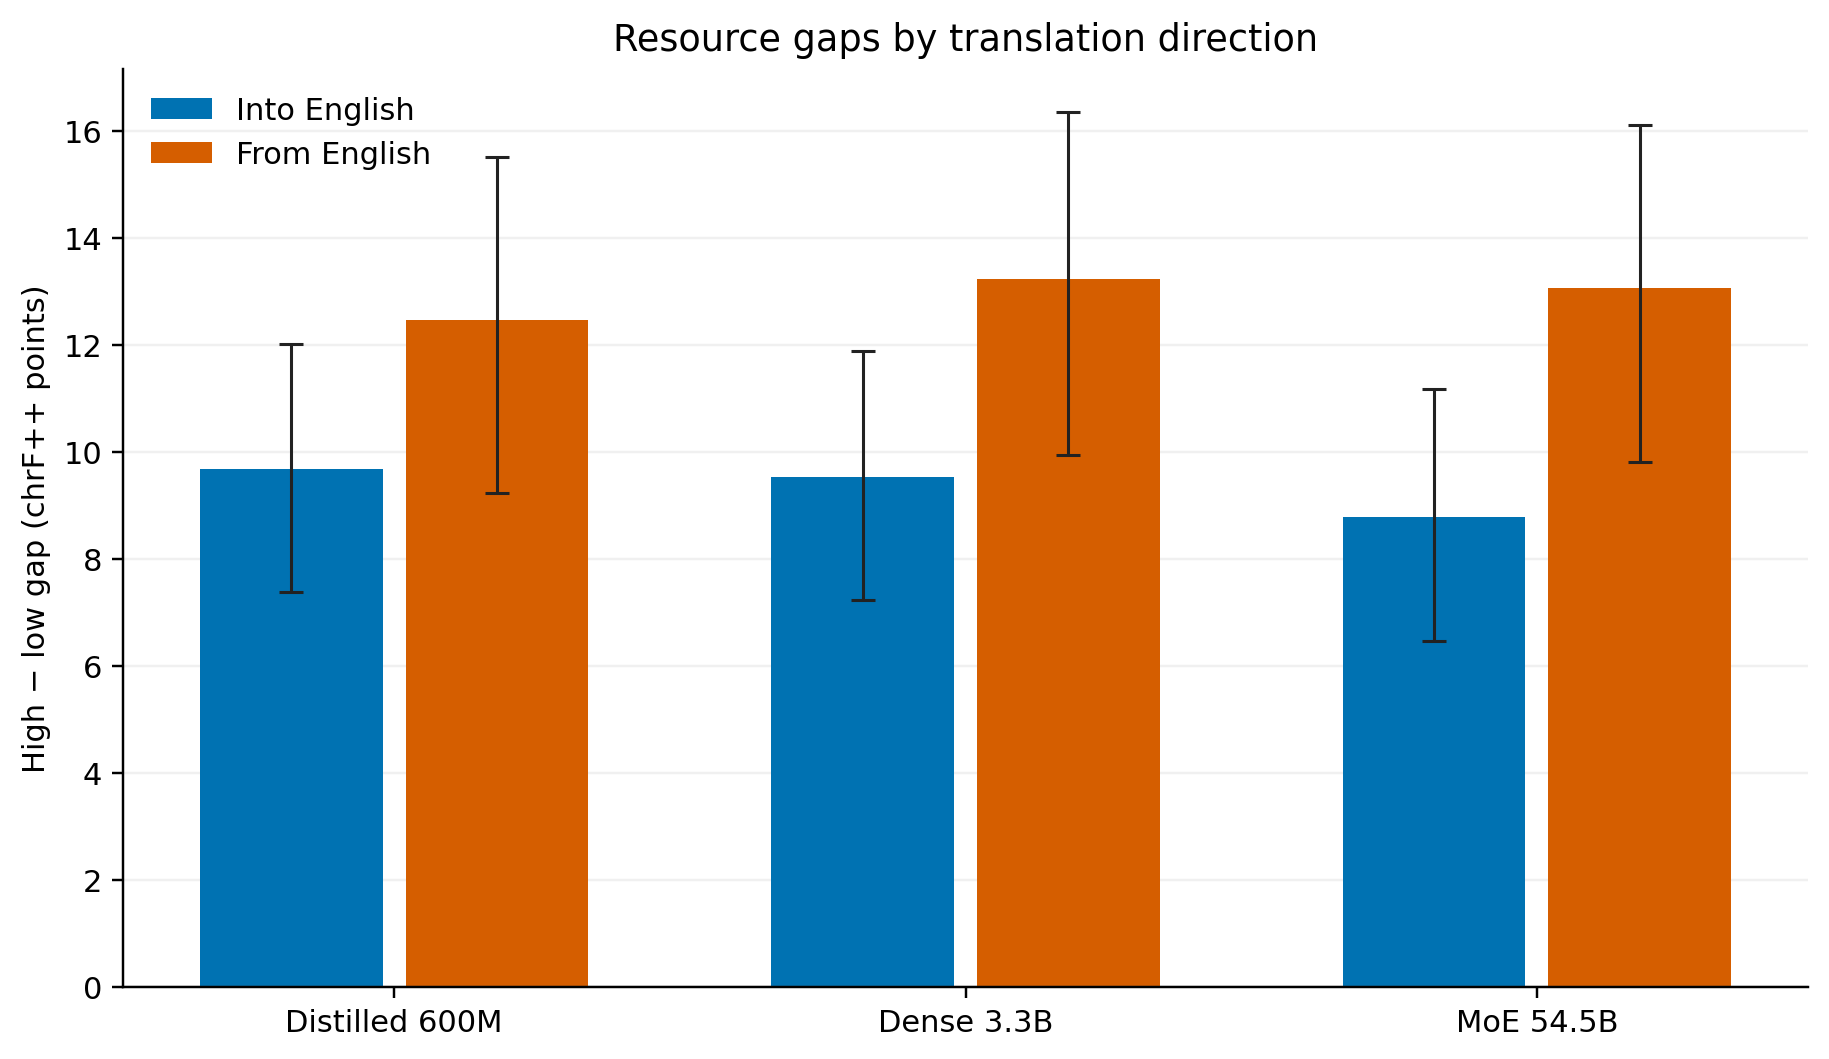

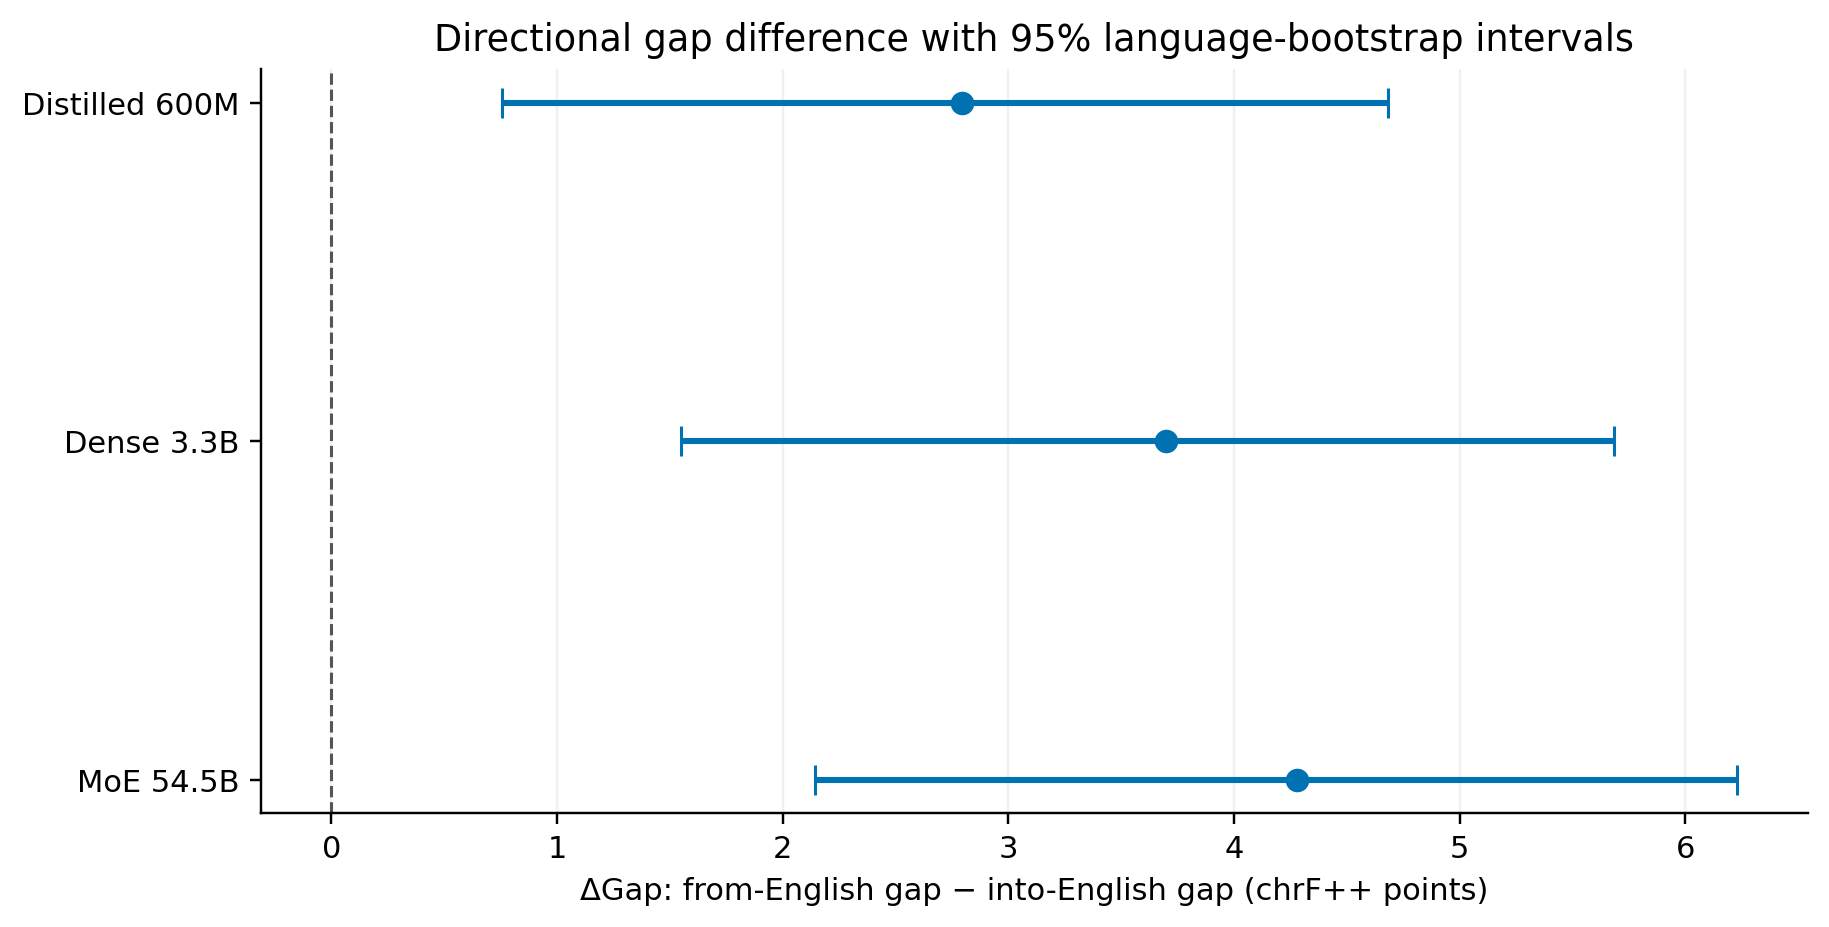

In [5]:
display(Image(filename=str(root / "figures/figure_1_resource_gaps.png"), width=750))
display(Image(filename=str(root / "figures/figure_2_delta_gap.png"), width=750))

## 3. Additional analysis

**Sensitivity checks:** equal weight for all 201 script units, medians instead of means, and removing one language at a time (195 times).
**Subgroups:** High, Low without Very low, and Very low (≤ 100,000 examples). `mean_direction_penalty` = average (into-English − from-English) score.

In [6]:
robust = pd.read_csv(results / "robustness.csv")
display(robust[["model", "primary_delta_gap", "script_weighted_delta_gap", "median_difference",
                "leave_one_out_min", "leave_one_out_max", "leave_one_out_sign_stable_count"]].round(2))  # Table 4

sub = pd.read_csv(results / "subgroup_results.csv")
display(sub[sub["model"] == "moe_54b"].round(2))

,model,primary_delta_gap,script_weighted_delta_gap,median_difference,leave_one_out_min,leave_one_out_max,leave_one_out_sign_stable_count
0,distilled_600m,2.8,2.41,2.8,2.58,3.32,195
1,dense_3b,3.7,3.24,3.2,3.5,4.25,195
2,moe_54b,4.28,3.89,4,4.09,4.85,195


,model,subgroup,n_languages,mean_into,mean_from,mean_direction_penalty
2,moe_54b,high,52,63.63,55.56,8.07
5,moe_54b,low,143,54.85,42.49,12.35
8,moe_54b,very_low,79,55.22,40.48,14.74
11,moe_54b,low_excluding_very_low,64,54.38,44.98,9.4


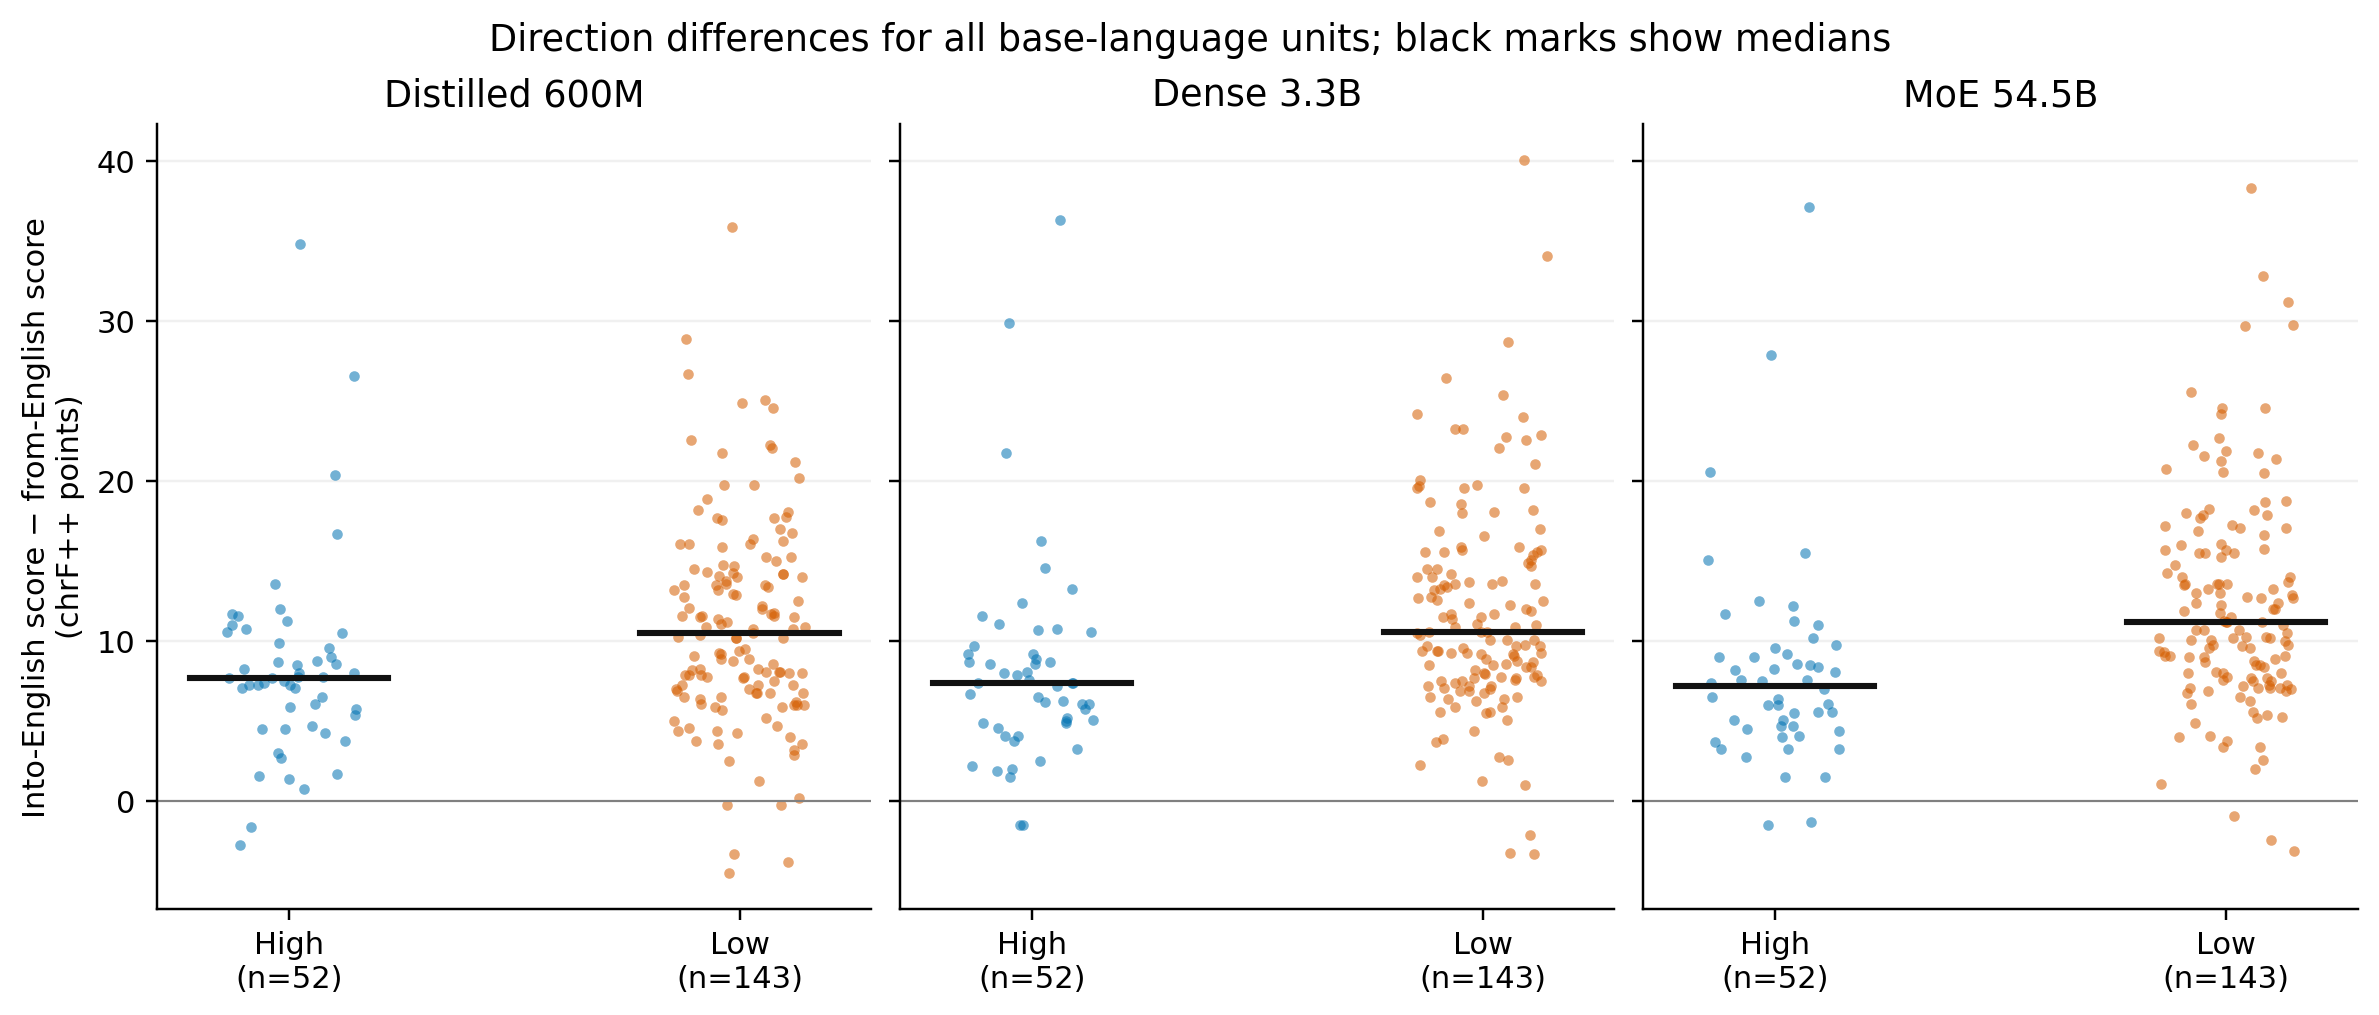

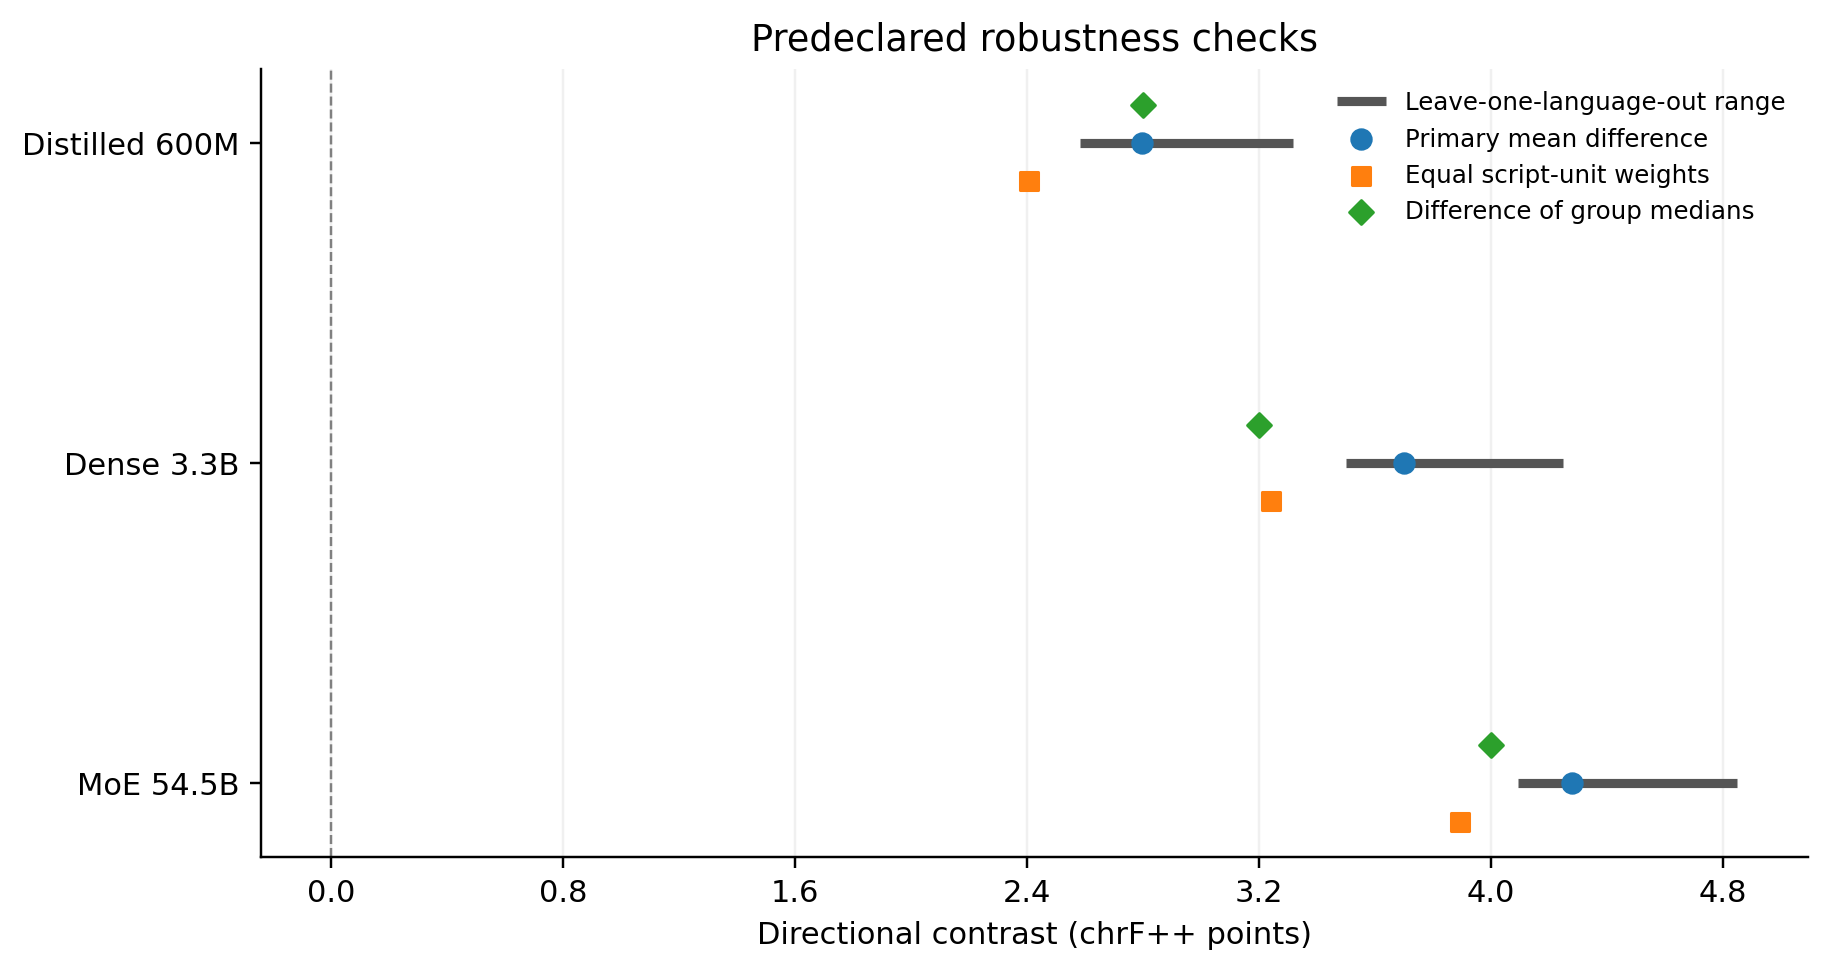

In [7]:
display(Image(filename=str(root / "figures/figure_3_language_differences.png"), width=750))
display(Image(filename=str(root / "figures/figure_4_robustness.png"), width=750))

## 4. Error analysis

60 MoE 54.5B translations into English (six low-resource languages, the 10 lowest sentence chrF++ scores per language) were reviewed and labelled as an error, an acceptable paraphrase, or uncertain. Each error has one dominant category.

In [8]:
errors = pd.read_csv(results / "error_audit/error_summary.csv")
display(errors[errors["section"].isin(["status", "error_type", "suspected_flag_by_status"])])

,section,item,count,percent_of_errors
0,status,confirmed_error,37,NaN
1,status,acceptable_paraphrase,8,NaN
2,status,uncertain,15,NaN
3,error_type,meaning substitution,25,67.6
4,error_type,omission or truncation,10,27
5,error_type,named entity or number error,1,2.7
6,error_type,unsupported addition or repetition,1,2.7
7,error_type,grammar or word-order defect,0,0
11,suspected_flag_by_status,confirmed_error,10,NaN
12,suspected_flag_by_status,uncertain,13,NaN


In [9]:
cases = pd.read_csv(results / "error_audit/reviewed_round_01.csv", keep_default_na=False)
for record in ["khm_Khmr-eng_Latn:0372", "mya_Mymr-eng_Latn:0137", "khm_Khmr-eng_Latn:0490"]:
    row = cases.set_index("record_id").loc[record]
    print(record, "|", row["annotation_status"], "|", row["dominant_error_type"] or "-")
    print("  Reference:", row["reference_text"])
    print("  Output:   ", row["hypothesis_text"], "\n")

khm_Khmr-eng_Latn:0372 | confirmed_error | omission or truncation
  Reference: They can see very well in the dark with night vision, and move very stealthily, too. Ocelots hunt their prey by blending in with their surroundings then pouncing on their prey.
  Output:    At night, they can see clearly and navigate smoothly. 

mya_Mymr-eng_Latn:0137 | acceptable_paraphrase | -
  Reference: Fire rescue crews eventually doused the fire by 11:35 pm.
  Output:    Firefighters finally extinguished the blaze at 11:35 p.m. 

khm_Khmr-eng_Latn:0490 | uncertain | -
  Reference: Its renown for being an epicenter of luxury began in about 400 A.D. and lasted up until about 1100 A.D.
  Output:    Renowned for its elegance, it began around 400 BC and continued until 1100 BC. 



## 5. Where each number comes from

| Number in the report | File |
|---|---|
| Group means, Gap, DeltaGap, 95% CI (Tables 2–3) | `results/main_summary.csv`, `results/main_results_long.csv` |
| p-values and Holm correction (Table 3) | `results/statistical_tests.csv` |
| Sensitivity checks (Table 4) | `results/robustness.csv`, `results/leave_one_out.csv` |
| Subgroups, medians, IQR | `results/subgroup_results.csv`, `results/diagnostics.csv` |
| Score of each language and its source row | `results/per_language_scores.csv` |
| Error counts (Appendix B) | `results/error_audit/error_summary.csv`, `reviewed_round_01.csv` |
| Run time and environment of the reported run | `results/run_log_2026-11-07.json` |